## Unsupervised Learning
**1. Clustering**
    
    1. k-means clustering
    
    2. Hierarchical clustering
    
    3. Density-based clustering

**2. Association Rule Learning**
    
    1. Apriori Algorithm
    
    2. Eclat Algorithm

**3. Dimensionality Reduction**
    
    1. Principal Component Analysis(PCA)
    
    2. Linear Discriminant Analysis(LDA)
    
    3. Isomap

In [2]:
import seaborn as sns

In [3]:
df = sns.load_dataset('iris')
df.head() 

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
df1 = df.iloc[:,:-1]
df1

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [5]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [6]:
from scipy import stats

In [7]:
stats.iqr(df1.sepal_width) 

0.5

In [8]:
IQR_sepal_width = stats.iqr(df1.sepal_width)

In [9]:
import numpy as np

In [10]:
Q1_sepal_width = np.percentile(df.sepal_width,25)
Q3_sepal_width = np.percentile(df.sepal_width, 75)

In [11]:
LB_sepal_width = Q1_sepal_width - 1.5 * IQR_sepal_width

In [12]:
UB_sepal_width = Q3_sepal_width + 1.5 * IQR_sepal_width

In [13]:
df1.loc[(df1.sepal_width>LB_sepal_width)&(df1.sepal_width<UB_sepal_width)]

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [14]:
df1.loc[df.sepal_width<LB_sepal_width]

,sepal_length,sepal_width,petal_length,petal_width
60,5.0,2.0,3.5,1.0


In [15]:
df1.loc[df.sepal_width>UB_sepal_width]

,sepal_length,sepal_width,petal_length,petal_width
15,5.7,4.4,1.5,0.4
32,5.2,4.1,1.5,0.1
33,5.5,4.2,1.4,0.2


In [16]:
((150-146)/150)*100

2.666666666666667

In [17]:
df.sepal_width.median()

3.0

In [18]:
df1.loc[df.sepal_width<LB_sepal_width] = 3.0

In [19]:
df1.loc[df.sepal_width>UB_sepal_width] = 3.0

In [79]:
df1

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


## EDA - Exploratory Data Anlysis

<Axes: >

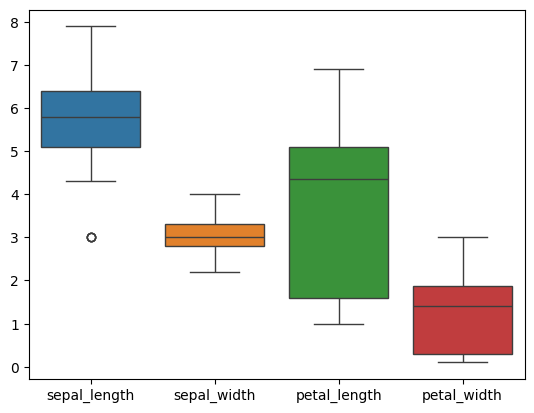

In [21]:
sns.boxplot(df1)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.099227      0.801386     0.494227
sepal_width      -0.099227     1.000000     -0.403693    -0.323890
petal_length      0.801386    -0.403693      1.000000     0.868538
petal_width       0.494227    -0.323890      0.868538     1.000000


<Axes: >

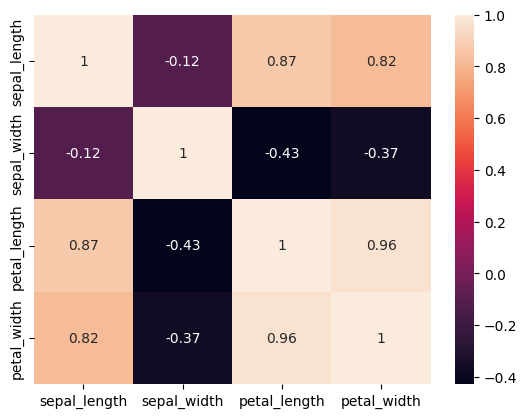

In [22]:
print(df1.corr())
sns.heatmap(df1.corr(numeric_only=True),annot=True)

In [23]:
## Kmeans
from sklearn.cluster import KMeans
model = KMeans()
model.fit(df1) 

KMeans()

In [24]:
model.cluster_centers_

array([[6.12222222, 2.7       , 4.76111111, 1.51111111],
       [4.97659574, 3.37659574, 1.46170213, 0.24680851],
       [7.475     , 3.125     , 6.3       , 2.05      ],
       [5.67272727, 2.83636364, 4.85454545, 1.84545455],
       [3.        , 3.        , 3.        , 3.        ],
       [5.56363636, 2.61363636, 3.87272727, 1.17727273],
       [6.58461538, 3.06153846, 4.62307692, 1.46923077],
       [6.56086957, 3.06956522, 5.52608696, 2.15217391]])

In [25]:
model = KMeans(n_clusters=3)
model.fit(df1)

KMeans(n_clusters=3)

In [26]:
model.cluster_centers_

array([[4.978     , 3.318     , 1.566     , 0.294     ],
       [6.31458333, 2.89583333, 4.97395833, 1.703125  ],
       [3.        , 3.        , 3.        , 3.        ]])

In [27]:
len(model.labels_)

150

In [28]:
 model.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [29]:
model = KMeans(n_clusters=4)
model.fit(df1)

KMeans(n_clusters=4)

In [30]:
model.cluster_centers_

array([[4.97659574, 3.37659574, 1.46170213, 0.24680851],
       [6.21363636, 2.85909091, 4.76818182, 1.60454545],
       [6.9125    , 3.1       , 5.846875  , 2.13125   ],
       [5.13333333, 2.67407407, 3.78518519, 1.47407407]])

In [31]:
model.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 3, 1, 1, 1, 3, 1, 3, 3, 1, 3, 1, 3, 1,
       1, 3, 1, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 1, 3, 1, 1, 1,
       3, 3, 3, 1, 3, 3, 3, 3, 3, 1, 3, 3, 2, 1, 2, 2, 2, 2, 3, 2, 2, 2,
       1, 1, 2, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 1, 1, 2, 1])

## Elbow Method

In [33]:
from scipy.spatial.distance import cdist
import numpy as np

In [34]:
error = []
for i in range(1,16):
    model = KMeans(n_clusters=i)
    model.fit(df1)
    dist = cdist(df1,model.cluster_centers_)
    act_dist = np.min(dist,axis = 1)      # act_dist is actual distance.s
    total_error = sum(act_dist)
    error.append(total_error)
error

[294.20727632536307,
 141.86569259990685,
 108.60742773371416,
 96.99483101787604,
 80.534926199593,
 74.8349882254373,
 66.59165921088821,
 67.68134933368802,
 63.33511527018206,
 57.506437330775576,
 55.40766253286305,
 54.12274044248779,
 53.404322626573915,
 50.636931148697315,
 50.85027830085511]

In [35]:
from matplotlib import pyplot as plt

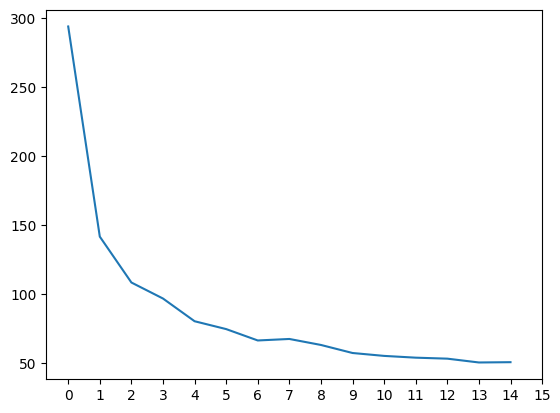

In [36]:
plt.plot(error)
plt.xticks(range(0,16))
plt.show()

In [37]:
model = KMeans(n_clusters=3) 
model.fit(df1)

KMeans(n_clusters=3)

In [38]:
model.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 2, 2, 1, 1, 1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 2, 1, 1, 1, 1,
       1, 2, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2])

### Model Evaluation

In [39]:
## Silhouette score
from sklearn.metrics import silhouette_score
ss = silhouette_score(df1,model.labels_) # model.labels_ is for k = 3
ss

0.5181872982249809

| Score Range    | Clustering Quality  | Meaning                             |
| -------------- | ------------------- | ----------------------------------- |
| 0.7 – 1.0      | Excellent           | Very clear, well-separated clusters |
| 0.5 – 0.7      | Good                | Clear structure but some overlap    |
| 0.25 – 0.5     | Moderate / Fair     | Some clusters overlap               |
| < 0.25         | Poor                | Clusters are mixing / unclear       |

### Applications of Clustering

| Domain       | What Clustering Does  |
| ------------ | --------------------- |
| Retail       | Customer segmentation |
| Banking      | Fraud detection       |
| Healthcare   | Patient grouping      |
| Vision       | Object/image grouping |
| NLP          | Topic modeling        |
| Social Media | Community detection   |